<a href="https://colab.research.google.com/github/SOURAVNEAL/Brain-stroke-prediction1/blob/main/Another_copy_of_Heart_Stroke.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import pandas as pd
data=pd.read_csv("/content/healthcare_dataset_stroke_data.csv")
data.head(10)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
5,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1
6,53882,Male,74.0,1,1,Yes,Private,Rural,70.09,27.4,never smoked,1
7,10434,Female,69.0,0,0,No,Private,Urban,94.39,22.8,never smoked,1
8,27419,Female,59.0,0,0,Yes,Private,Rural,76.15,NaN,Unknown,1
9,60491,Female,78.0,0,0,Yes,Private,Urban,58.57,24.2,Unknown,1


In [25]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn.model_selection import train_test_split

# 1. Load Data
data = pd.read_csv("/content/healthcare_dataset_stroke_data.csv")

# 2. Drop 'id' column
x = data.drop('id', axis=1)

# 3. Handle Null Values using Interpolation
df_for_interpolation = pd.DataFrame(x.copy())
df_for_interpolation['bmi'] = df_for_interpolation['bmi'].interpolate(method='linear', axis=0)
data1 = df_for_interpolation # Renaming to data1 as used in original notebook

# 4. Label Encode Categorical Data
label_encoder = LabelEncoder()
encoded_data = data1.copy()
label_mapping = {}  # Store mapping between original labels and encoded values
for col in data1.columns:
    if data1[col].dtype == 'object':
        encoded_data[col] = label_encoder.fit_transform(data1[col])
        label_mapping[col] = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))

print("Encoded DataFrame head:")
print(encoded_data.head())

# 5. Apply SMOTE Resampling
X = encoded_data.drop(columns=['stroke'])
y = encoded_data['stroke']
smote = SMOTE()
X_resampled, y_resampled = smote.fit_resample(X, y)

print("\nClass distribution after SMOTE:")
print(pd.Series(y_resampled).value_counts())

# 6. Lasso Feature Selection (using LogisticRegression with L1 penalty for feature selection as in notebook)
lasso_model_for_selection = LogisticRegression(penalty='l1', solver='liblinear', random_state=42)
lasso_model_for_selection.fit(X_resampled, y_resampled)

lasso_coefs = lasso_model_for_selection.coef_[0]
feature_names = X_resampled.columns
lasso_results = pd.DataFrame({'Feature': feature_names, 'Lasso Coefficient': lasso_coefs})
lasso_results_sorted = lasso_results.reindex(lasso_results['Lasso Coefficient'].abs().sort_values(ascending=False).index)
top_5_features = lasso_results_sorted.head(5)

print("\nTop 5 features based on Lasso coefficients:")
print(top_5_features)

# 7. Extract selected features and perform Train-Test Split
X_selected = X_resampled[top_5_features['Feature']]
X_train, X_test, y_train, y_test = train_test_split(X_selected, y_resampled, test_size=0.2, random_state=42)

print("\nTraining set shape:", X_train.shape, y_train.shape)
print("Testing set shape:", X_test.shape, y_test.shape)

Encoded DataFrame head:
   gender   age  hypertension  heart_disease  ever_married  work_type  \
0       1  67.0             0              1             1          2   
1       0  61.0             0              0             1          3   
2       1  80.0             0              1             1          2   
3       0  49.0             0              0             1          2   
4       0  79.0             1              0             1          3   

   Residence_type  avg_glucose_level    bmi  smoking_status  stroke  
0               1             228.69  36.60               1       1  
1               0             202.21  34.55               2       1  
2               0             105.92  32.50               2       1  
3               1             171.23  34.40               3       1  
4               0             174.12  24.00               2       1  

Class distribution after SMOTE:
stroke
1    4861
0    4861
Name: count, dtype: int64

Top 5 features based on Lasso 

In [26]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# 1. Load Data
data = pd.read_csv("/content/healthcare_dataset_stroke_data.csv")

# 2. Drop 'id' column
x = data.drop('id', axis=1)

# 3. Handle Null Values using Interpolation
df_for_interpolation = pd.DataFrame(x.copy())
df_for_interpolation['bmi'] = df_for_interpolation['bmi'].interpolate(method='linear', axis=0)
data1 = df_for_interpolation # Renaming to data1 as used in original notebook

# 4. Label Encode Categorical Data
label_encoder = LabelEncoder()
encoded_data = data1.copy()
label_mapping = {}  # Store mapping between original labels and encoded values
for col in data1.columns:
    if data1[col].dtype == 'object':
        encoded_data[col] = label_encoder.fit_transform(data1[col])
        label_mapping[col] = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))

print("Encoded DataFrame head:")
print(encoded_data.head())

# 5. Apply SMOTE Resampling
X = encoded_data.drop(columns=['stroke'])
y = encoded_data['stroke']
smote = SMOTE()
X_resampled, y_resampled = smote.fit_resample(X, y)

print("\nClass distribution after SMOTE:")
print(pd.Series(y_resampled).value_counts())

# 6. Lasso Feature Selection (using LogisticRegression with L1 penalty for feature selection as in notebook)
# Note: The original notebook used LogisticRegression with L1 for feature selection, not Lasso directly.
lasso_model_for_selection = LogisticRegression(penalty='l1', solver='liblinear', random_state=42)
lasso_model_for_selection.fit(X_resampled, y_resampled)

lasso_coefs = lasso_model_for_selection.coef_[0]
feature_names = X_resampled.columns
lasso_results = pd.DataFrame({'Feature': feature_names, 'Lasso Coefficient': lasso_coefs})
lasso_results_sorted = lasso_results.reindex(lasso_results['Lasso Coefficient'].abs().sort_values(ascending=False).index)
top_5_features = lasso_results_sorted.head(5)

print("\nTop 5 features based on Lasso coefficients:")
print(top_5_features)

# 7. Extract selected features and perform Train-Test Split
X_selected = X_resampled[top_5_features['Feature']]
X_train, X_test, y_train, y_test = train_test_split(X_selected, y_resampled, test_size=0.2, random_state=42)

print("\nTraining set shape:", X_train.shape, y_train.shape)
print("Testing set shape:", X_test.shape, y_test.shape)

Encoded DataFrame head:
   gender   age  hypertension  heart_disease  ever_married  work_type  \
0       1  67.0             0              1             1          2   
1       0  61.0             0              0             1          3   
2       1  80.0             0              1             1          2   
3       0  49.0             0              0             1          2   
4       0  79.0             1              0             1          3   

   Residence_type  avg_glucose_level    bmi  smoking_status  stroke  
0               1             228.69  36.60               1       1  
1               0             202.21  34.55               2       1  
2               0             105.92  32.50               2       1  
3               1             171.23  34.40               3       1  
4               0             174.12  24.00               2       1  

Class distribution after SMOTE:
stroke
1    4861
0    4861
Name: count, dtype: int64

Top 5 features based on Lasso 


--- Stacked Ensemble with Decision Tree as Meta-Learner ---
Accuracy (Stacked - DT Meta): 0.6575835475578407
Classification Report (Stacked - DT Meta):
               precision    recall  f1-score   support

           0       0.65      0.69      0.67       975
           1       0.67      0.63      0.65       970

    accuracy                           0.66      1945
   macro avg       0.66      0.66      0.66      1945
weighted avg       0.66      0.66      0.66      1945



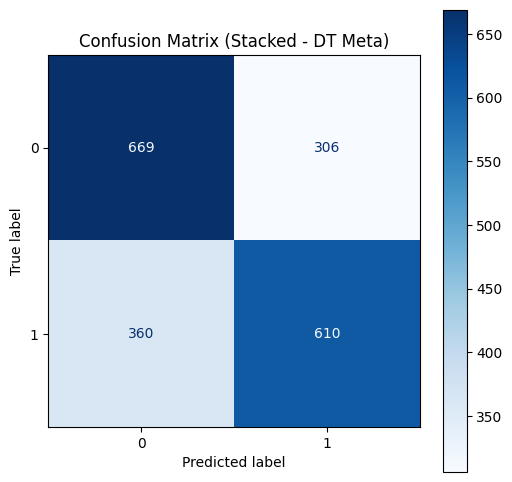

In [27]:
import pandas as pd
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

print("\n--- Stacked Ensemble with Decision Tree as Meta-Learner ---")

# Define base classifiers
xgb_classifier_dt = XGBClassifier(random_state=42)
rf_classifier_dt = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the base classifiers
xgb_classifier_dt.fit(X_train, y_train)
rf_classifier_dt.fit(X_train, y_train)

# Generate predictions from base classifiers for training meta-learner
xgb_pred_dt = xgb_classifier_dt.predict(X_train)
rf_pred_dt = rf_classifier_dt.predict(X_train)
X_train_stacked_dt = pd.DataFrame({'XGB_Pred': xgb_pred_dt, 'RF_Pred': rf_pred_dt})

# Define the Decision Tree as the meta-learner
dt_meta_learner = DecisionTreeClassifier(random_state=42)

# Train the stacked ensemble
stacked_classifier_dt = StackingClassifier(estimators=[('XGB', xgb_classifier_dt), ('RF', rf_classifier_dt)], final_estimator=dt_meta_learner)
stacked_classifier_dt.fit(X_train_stacked_dt, y_train)

# Make predictions on the test set
xgb_pred_test_dt = xgb_classifier_dt.predict(X_test)
rf_pred_test_dt = rf_classifier_dt.predict(X_test)
X_test_stacked_dt = pd.DataFrame({'XGB_Pred': xgb_pred_test_dt, 'RF_Pred': rf_pred_test_dt})
y_pred_stacked_dt = stacked_classifier_dt.predict(X_test_stacked_dt)

# Evaluate the stacked ensemble
accuracy_stacked_dt = accuracy_score(y_test, y_pred_stacked_dt)
print("Accuracy (Stacked - DT Meta):", accuracy_stacked_dt)
print("Classification Report (Stacked - DT Meta):\n", classification_report(y_test, y_pred_stacked_dt))

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_stacked_dt, ax=ax, cmap=plt.cm.Blues)
ax.set_title('Confusion Matrix (Stacked - DT Meta)')
plt.show()



--- Stacked Ensemble with KNN as Meta-Learner ---
Accuracy (Stacked - KNN Meta): 0.5012853470437018
Classification Report (Stacked - KNN Meta):
               precision    recall  f1-score   support

           0       0.50      1.00      0.67       975
           1       0.00      0.00      0.00       970

    accuracy                           0.50      1945
   macro avg       0.25      0.50      0.33      1945
weighted avg       0.25      0.50      0.33      1945



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


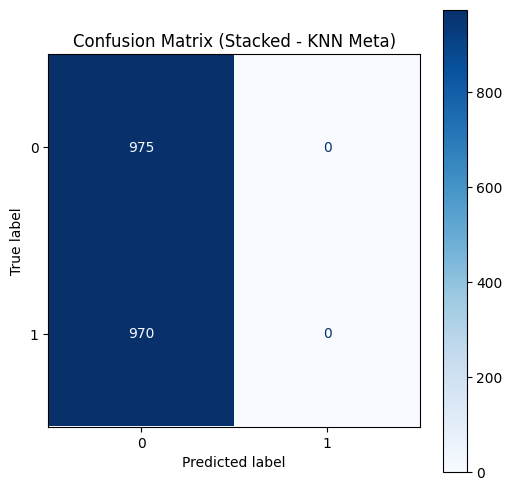

In [28]:
import pandas as pd
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

print("\n--- Stacked Ensemble with KNN as Meta-Learner ---")

# Define base classifiers
xgb_classifier_knn = XGBClassifier(random_state=42)
rf_classifier_knn = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the base classifiers (re-training for clarity/independence)
xgb_classifier_knn.fit(X_train, y_train)
rf_classifier_knn.fit(X_train, y_train)

# Generate predictions from base classifiers for training meta-learner
xgb_pred_knn = xgb_classifier_knn.predict(X_train)
rf_pred_knn = rf_classifier_knn.predict(X_train)
X_train_stacked_knn = pd.DataFrame({'XGB_Pred': xgb_pred_knn, 'RF_Pred': rf_pred_knn})

# Define the KNN as the meta-learner
knn_meta_learner = KNeighborsClassifier()

# Train the stacked ensemble
stacked_classifier_knn = StackingClassifier(estimators=[('XGB', xgb_classifier_knn), ('RF', rf_classifier_knn)], final_estimator=knn_meta_learner)
stacked_classifier_knn.fit(X_train_stacked_knn, y_train)

# Make predictions on the test set
xgb_pred_test_knn = xgb_classifier_knn.predict(X_test)
rf_pred_test_knn = rf_classifier_knn.predict(X_test)
X_test_stacked_knn = pd.DataFrame({'XGB_Pred': xgb_pred_test_knn, 'RF_Pred': rf_pred_test_knn})
y_pred_stacked_knn = stacked_classifier_knn.predict(X_test_stacked_knn)

# Evaluate the stacked ensemble
accuracy_stacked_knn = accuracy_score(y_test, y_pred_stacked_knn)
print("Accuracy (Stacked - KNN Meta):", accuracy_stacked_knn)
print("Classification Report (Stacked - KNN Meta):\n", classification_report(y_test, y_pred_stacked_knn))

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_stacked_knn, ax=ax, cmap=plt.cm.Blues)
ax.set_title('Confusion Matrix (Stacked - KNN Meta)')
plt.show()



--- Stacked Ensemble with Logistic Regression as Meta-Learner ---
Accuracy (Stacked - LR Meta): 0.6575835475578407
Classification Report (Stacked - LR Meta):
               precision    recall  f1-score   support

           0       0.65      0.69      0.67       975
           1       0.67      0.63      0.65       970

    accuracy                           0.66      1945
   macro avg       0.66      0.66      0.66      1945
weighted avg       0.66      0.66      0.66      1945



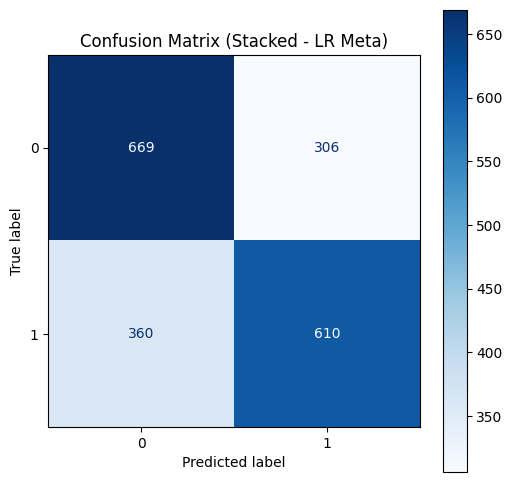

In [29]:
import pandas as pd
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

print("\n--- Stacked Ensemble with Logistic Regression as Meta-Learner ---")

# Define base classifiers
xgb_classifier_lr = XGBClassifier(random_state=42)
rf_classifier_lr = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the base classifiers (re-training for clarity/independence)
xgb_classifier_lr.fit(X_train, y_train)
rf_classifier_lr.fit(X_train, y_train)

# Generate predictions from base classifiers for training meta-learner
xgb_pred_lr = xgb_classifier_lr.predict(X_train)
rf_pred_lr = rf_classifier_lr.predict(X_train)
X_train_stacked_lr = pd.DataFrame({'XGB_Pred': xgb_pred_lr, 'RF_Pred': rf_pred_lr})

# Define Logistic Regression as the meta-learner
lr_meta_learner = LogisticRegression()

# Train the stacked ensemble
stacked_classifier_lr = StackingClassifier(estimators=[('XGB', xgb_classifier_lr), ('RF', rf_classifier_lr)], final_estimator=lr_meta_learner)
stacked_classifier_lr.fit(X_train_stacked_lr, y_train)

# Make predictions on the test set
xgb_pred_test_lr = xgb_classifier_lr.predict(X_test)
rf_pred_test_lr = rf_classifier_lr.predict(X_test)
X_test_stacked_lr = pd.DataFrame({'XGB_Pred': xgb_pred_test_lr, 'RF_Pred': rf_pred_test_lr})
y_pred_stacked_lr = stacked_classifier_lr.predict(X_test_stacked_lr)

# Evaluate the stacked ensemble
accuracy_stacked_lr = accuracy_score(y_test, y_pred_stacked_lr)
print("Accuracy (Stacked - LR Meta):", accuracy_stacked_lr)
print("Classification Report (Stacked - LR Meta):\n", classification_report(y_test, y_pred_stacked_lr))

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_stacked_lr, ax=ax, cmap=plt.cm.Blues)
ax.set_title('Confusion Matrix (Stacked - LR Meta)')
plt.show()


--- Stacked Ensemble with Decision Tree as Meta-Learner ---
Accuracy (Stacked - DT Meta): 0.6575835475578407
Classification Report (Stacked - DT Meta):
               precision    recall  f1-score   support

           0       0.65      0.69      0.67       975
           1       0.67      0.63      0.65       970

    accuracy                           0.66      1945
   macro avg       0.66      0.66      0.66      1945
weighted avg       0.66      0.66      0.66      1945



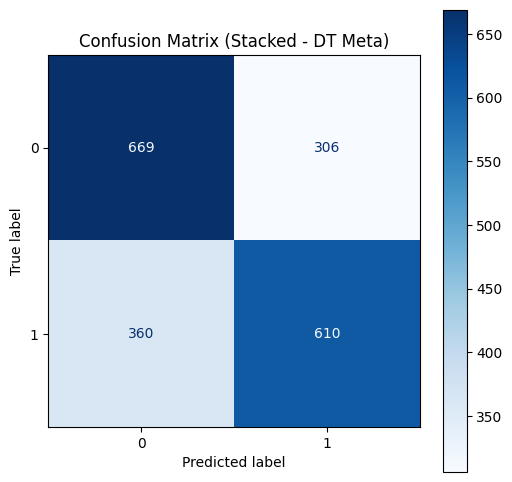

In [30]:
import pandas as pd
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

print("\n--- Stacked Ensemble with Decision Tree as Meta-Learner ---")

# Define base classifiers
xgb_classifier_dt = XGBClassifier(random_state=42)
rf_classifier_dt = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the base classifiers
xgb_classifier_dt.fit(X_train, y_train)
rf_classifier_dt.fit(X_train, y_train)

# Generate predictions from base classifiers for training meta-learner
xgb_pred_dt = xgb_classifier_dt.predict(X_train)
rf_pred_dt = rf_classifier_dt.predict(X_train)
X_train_stacked_dt = pd.DataFrame({'XGB_Pred': xgb_pred_dt, 'RF_Pred': rf_pred_dt})

# Define the Decision Tree as the meta-learner
dt_meta_learner = DecisionTreeClassifier(random_state=42)

# Train the stacked ensemble
stacked_classifier_dt = StackingClassifier(estimators=[('XGB', xgb_classifier_dt), ('RF', rf_classifier_dt)], final_estimator=dt_meta_learner)
stacked_classifier_dt.fit(X_train_stacked_dt, y_train)

# Make predictions on the test set
xgb_pred_test_dt = xgb_classifier_dt.predict(X_test)
rf_pred_test_dt = rf_classifier_dt.predict(X_test)
X_test_stacked_dt = pd.DataFrame({'XGB_Pred': xgb_pred_test_dt, 'RF_Pred': rf_pred_test_dt})
y_pred_stacked_dt = stacked_classifier_dt.predict(X_test_stacked_dt)

# Evaluate the stacked ensemble
accuracy_stacked_dt = accuracy_score(y_test, y_pred_stacked_dt)
print("Accuracy (Stacked - DT Meta):", accuracy_stacked_dt)
print("Classification Report (Stacked - DT Meta):\n", classification_report(y_test, y_pred_stacked_dt))

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_stacked_dt, ax=ax, cmap=plt.cm.Blues)
ax.set_title('Confusion Matrix (Stacked - DT Meta)')
plt.show()


--- Stacked Ensemble with KNN as Meta-Learner ---
Accuracy (Stacked - KNN Meta): 0.5012853470437018
Classification Report (Stacked - KNN Meta):
               precision    recall  f1-score   support

           0       0.50      1.00      0.67       975
           1       0.00      0.00      0.00       970

    accuracy                           0.50      1945
   macro avg       0.25      0.50      0.33      1945
weighted avg       0.25      0.50      0.33      1945



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


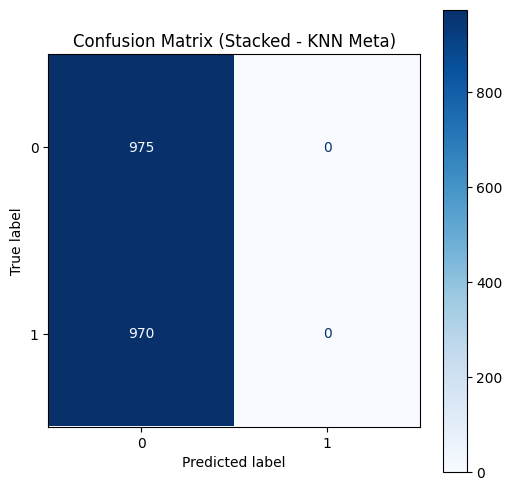

In [31]:
import pandas as pd
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

print("\n--- Stacked Ensemble with KNN as Meta-Learner ---")

# Define base classifiers
xgb_classifier_knn = XGBClassifier(random_state=42)
rf_classifier_knn = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the base classifiers (re-training for clarity/independence)
xgb_classifier_knn.fit(X_train, y_train)
rf_classifier_knn.fit(X_train, y_train)

# Generate predictions from base classifiers for training meta-learner
xgb_pred_knn = xgb_classifier_knn.predict(X_train)
rf_pred_knn = rf_classifier_knn.predict(X_train)
X_train_stacked_knn = pd.DataFrame({'XGB_Pred': xgb_pred_knn, 'RF_Pred': rf_pred_knn})

# Define the KNN as the meta-learner
knn_meta_learner = KNeighborsClassifier()

# Train the stacked ensemble
stacked_classifier_knn = StackingClassifier(estimators=[('XGB', xgb_classifier_knn), ('RF', rf_classifier_knn)], final_estimator=knn_meta_learner)
stacked_classifier_knn.fit(X_train_stacked_knn, y_train)

# Make predictions on the test set
xgb_pred_test_knn = xgb_classifier_knn.predict(X_test)
rf_pred_test_knn = rf_classifier_knn.predict(X_test)
X_test_stacked_knn = pd.DataFrame({'XGB_Pred': xgb_pred_test_knn, 'RF_Pred': rf_pred_test_knn})
y_pred_stacked_knn = stacked_classifier_knn.predict(X_test_stacked_knn)

# Evaluate the stacked ensemble
accuracy_stacked_knn = accuracy_score(y_test, y_pred_stacked_knn)
print("Accuracy (Stacked - KNN Meta):", accuracy_stacked_knn)
print("Classification Report (Stacked - KNN Meta):\n", classification_report(y_test, y_pred_stacked_knn))

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_stacked_knn, ax=ax, cmap=plt.cm.Blues)
ax.set_title('Confusion Matrix (Stacked - KNN Meta)')
plt.show()


--- Stacked Ensemble with Logistic Regression as Meta-Learner ---
Accuracy (Stacked - LR Meta): 0.6575835475578407
Classification Report (Stacked - LR Meta):
               precision    recall  f1-score   support

           0       0.65      0.69      0.67       975
           1       0.67      0.63      0.65       970

    accuracy                           0.66      1945
   macro avg       0.66      0.66      0.66      1945
weighted avg       0.66      0.66      0.66      1945



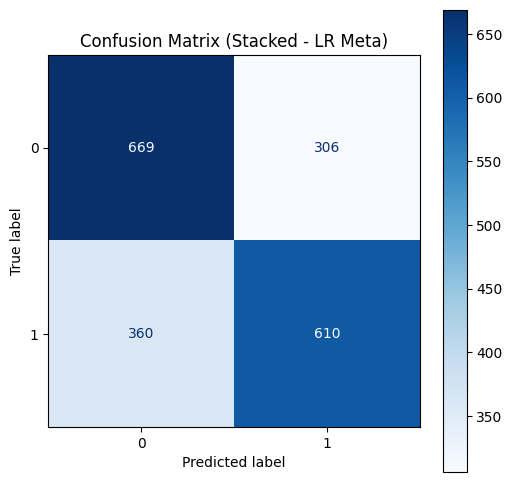

In [32]:
import pandas as pd
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

print("\n--- Stacked Ensemble with Logistic Regression as Meta-Learner ---")

# Define base classifiers
xgb_classifier_lr = XGBClassifier(random_state=42)
rf_classifier_lr = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the base classifiers (re-training for clarity/independence)
xgb_classifier_lr.fit(X_train, y_train)
rf_classifier_lr.fit(X_train, y_train)

# Generate predictions from base classifiers for training meta-learner
xgb_pred_lr = xgb_classifier_lr.predict(X_train)
rf_pred_lr = rf_classifier_lr.predict(X_train)
X_train_stacked_lr = pd.DataFrame({'XGB_Pred': xgb_pred_lr, 'RF_Pred': rf_pred_lr})

# Define Logistic Regression as the meta-learner
lr_meta_learner = LogisticRegression()

# Train the stacked ensemble
stacked_classifier_lr = StackingClassifier(estimators=[('XGB', xgb_classifier_lr), ('RF', rf_classifier_lr)], final_estimator=lr_meta_learner)
stacked_classifier_lr.fit(X_train_stacked_lr, y_train)

# Make predictions on the test set
xgb_pred_test_lr = xgb_classifier_lr.predict(X_test)
rf_pred_test_lr = rf_classifier_lr.predict(X_test)
X_test_stacked_lr = pd.DataFrame({'XGB_Pred': xgb_pred_test_lr, 'RF_Pred': rf_pred_test_lr})
y_pred_stacked_lr = stacked_classifier_lr.predict(X_test_stacked_lr)

# Evaluate the stacked ensemble
accuracy_stacked_lr = accuracy_score(y_test, y_pred_stacked_lr)
print("Accuracy (Stacked - LR Meta):", accuracy_stacked_lr)
print("Classification Report (Stacked - LR Meta):\n", classification_report(y_test, y_pred_stacked_lr))

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_stacked_lr, ax=ax, cmap=plt.cm.Blues)
ax.set_title('Confusion Matrix (Stacked - LR Meta)')
plt.show()


In [33]:
from sklearn.model_selection import train_test_split

# Assuming top_5_features contains the top 5 features selected from Lasso regression

# Extract the selected features from X_resampled
X_selected = X_resampled[top_5_features['Feature']]

# Divide the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_selected, y_resampled, test_size=0.2, random_state=42)

# Print the shapes of the training and testing sets
print("Training set shape:", X_train.shape, y_train.shape)
print("Testing set shape:", X_test.shape, y_test.shape)

Training set shape: (7777, 5) (7777,)
Testing set shape: (1945, 5) (1945,)


Accuracy (Stacked - DT Meta): 0.6575835475578407


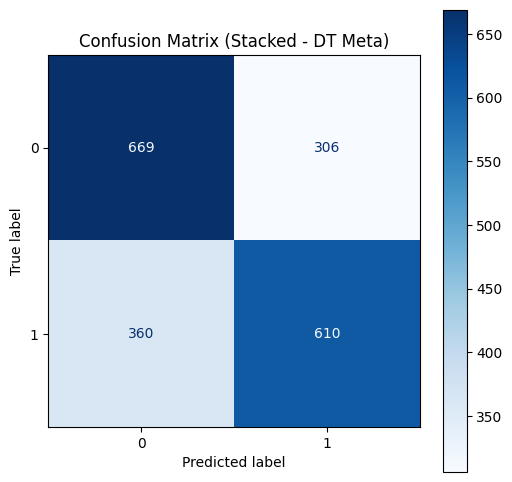

In [34]:
# Import necessary libraries
import pandas as pd
from sklearn.ensemble import StackingClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Define base classifiers (XGBoost and Random Forest)
xgb_classifier_dt = XGBClassifier(random_state=42)
rf_classifier_dt = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the base classifiers
xgb_classifier_dt.fit(X_train, y_train)
rf_classifier_dt.fit(X_train, y_train)

# Generate predictions from base classifiers
xgb_pred_dt = xgb_classifier_dt.predict(X_train)
rf_pred_dt = rf_classifier_dt.predict(X_train)

# Create a new feature matrix containing predictions of base classifiers
X_train_stacked_dt = pd.DataFrame({'XGB_Pred': xgb_pred_dt, 'RF_Pred': rf_pred_dt})

# Define the Decision Tree as the meta-learner
dt_meta_learner = DecisionTreeClassifier(random_state=42)

# Train the stacked ensemble
stacked_classifier_dt = StackingClassifier(estimators=[('XGB', xgb_classifier_dt), ('RF', rf_classifier_dt)], final_estimator=dt_meta_learner)
stacked_classifier_dt.fit(X_train_stacked_dt, y_train)

# Make predictions on the test set
xgb_pred_test_dt = xgb_classifier_dt.predict(X_test)
rf_pred_test_dt = rf_classifier_dt.predict(X_test)
X_test_stacked_dt = pd.DataFrame({'XGB_Pred': xgb_pred_test_dt, 'RF_Pred': rf_pred_test_dt})
y_pred_stacked_dt = stacked_classifier_dt.predict(X_test_stacked_dt)

# Evaluate the stacked ensemble
accuracy_stacked_dt = accuracy_score(y_test, y_pred_stacked_dt)
print("Accuracy (Stacked - DT Meta):", accuracy_stacked_dt)

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_stacked_dt, ax=ax, cmap=plt.cm.Blues)
ax.set_title('Confusion Matrix (Stacked - DT Meta)')
plt.show()

Accuracy (Stacked - KNN Meta): 0.5012853470437018


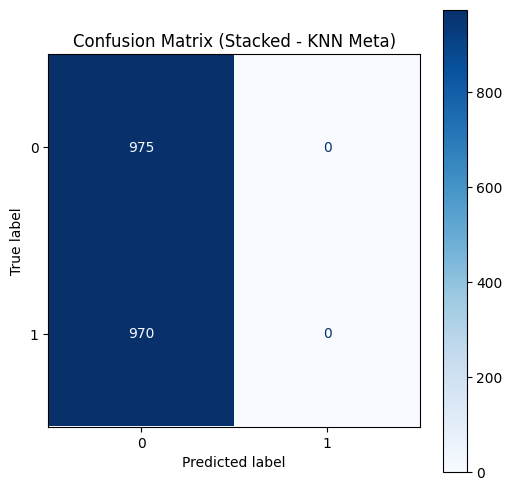

In [35]:
# Import necessary libraries
import pandas as pd
from sklearn.ensemble import StackingClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Define base classifiers (XGBoost and Random Forest)
xgb_classifier_knn = XGBClassifier(random_state=42)
rf_classifier_knn = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the base classifiers
xgb_classifier_knn.fit(X_train, y_train)
rf_classifier_knn.fit(X_train, y_train)

# Generate predictions from base classifiers
xgb_pred_knn = xgb_classifier_knn.predict(X_train)
rf_pred_knn = rf_classifier_knn.predict(X_train)

# Create a new feature matrix containing predictions of base classifiers
X_train_stacked_knn = pd.DataFrame({'XGB_Pred': xgb_pred_knn, 'RF_Pred': rf_pred_knn})

# Define the KNN as the meta-learner
knn_meta_learner = KNeighborsClassifier()

# Train the stacked ensemble
stacked_classifier_knn = StackingClassifier(estimators=[('XGB', xgb_classifier_knn), ('RF', rf_classifier_knn)], final_estimator=knn_meta_learner)
stacked_classifier_knn.fit(X_train_stacked_knn, y_train)

# Make predictions on the test set
xgb_pred_test_knn = xgb_classifier_knn.predict(X_test)
rf_pred_test_knn = rf_classifier_knn.predict(X_test)
X_test_stacked_knn = pd.DataFrame({'XGB_Pred': xgb_pred_test_knn, 'RF_Pred': rf_pred_test_knn})
y_pred_stacked_knn = stacked_classifier_knn.predict(X_test_stacked_knn)

# Evaluate the stacked ensemble
accuracy_stacked_knn = accuracy_score(y_test, y_pred_stacked_knn)
print("Accuracy (Stacked - KNN Meta):", accuracy_stacked_knn)

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_stacked_knn, ax=ax, cmap=plt.cm.Blues)
ax.set_title('Confusion Matrix (Stacked - KNN Meta)')
plt.show()

Accuracy (Stacked - LR Meta): 0.6575835475578407


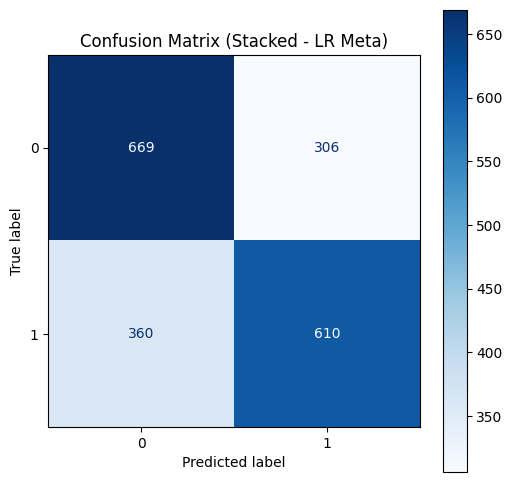

In [36]:
# Import necessary libraries
import pandas as pd
from sklearn.ensemble import StackingClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Define base classifiers (XGBoost and Random Forest)
xgb_classifier_lr = XGBClassifier(random_state=42)
rf_classifier_lr = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the base classifiers
xgb_classifier_lr.fit(X_train, y_train)
rf_classifier_lr.fit(X_train, y_train)

# Generate predictions from base classifiers
xgb_pred_lr = xgb_classifier_lr.predict(X_train)
rf_pred_lr = rf_classifier_lr.predict(X_train)

# Create a new feature matrix containing predictions of base classifiers
X_train_stacked_lr = pd.DataFrame({'XGB_Pred': xgb_pred_lr, 'RF_Pred': rf_pred_lr})

# Define Logistic Regression as the meta-learner
lr_meta_learner = LogisticRegression()

# Train the stacked ensemble
stacked_classifier_lr = StackingClassifier(estimators=[('XGB', xgb_classifier_lr), ('RF', rf_classifier_lr)], final_estimator=lr_meta_learner)
stacked_classifier_lr.fit(X_train_stacked_lr, y_train)

# Make predictions on the test set
xgb_pred_test_lr = xgb_classifier_lr.predict(X_test)
rf_pred_test_lr = rf_classifier_lr.predict(X_test)
X_test_stacked_lr = pd.DataFrame({'XGB_Pred': xgb_pred_test_lr, 'RF_Pred': rf_pred_test_lr})
y_pred_stacked_lr = stacked_classifier_lr.predict(X_test_stacked_lr)

# Evaluate the stacked ensemble
accuracy_stacked_lr = accuracy_score(y_test, y_pred_stacked_lr)
print("Accuracy (Stacked - LR Meta):", accuracy_stacked_lr)

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_stacked_lr, ax=ax, cmap=plt.cm.Blues)
ax.set_title('Confusion Matrix (Stacked - LR Meta)')
plt.show()

In [37]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [38]:
data.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


In [39]:
data.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [40]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [41]:
x=data.drop('id',axis=1)

Interpolation Technique to remove Null Values

In [42]:
import pandas as pd
df = pd.DataFrame(x)

# Perform linear interpolation along the columns
data1 = df.interpolate(method='linear', axis=0)

print("Original dataset:")
print(df)
print("\nInterpolated dataset:")
print(data1)

Original dataset:
      gender   age  hypertension  heart_disease ever_married      work_type  \
0       Male  67.0             0              1          Yes        Private   
1     Female  61.0             0              0          Yes  Self-employed   
2       Male  80.0             0              1          Yes        Private   
3     Female  49.0             0              0          Yes        Private   
4     Female  79.0             1              0          Yes  Self-employed   
...      ...   ...           ...            ...          ...            ...   
5105  Female  80.0             1              0          Yes        Private   
5106  Female  81.0             0              0          Yes  Self-employed   
5107  Female  35.0             0              0          Yes  Self-employed   
5108    Male  51.0             0              0          Yes        Private   
5109  Female  44.0             0              0          Yes       Govt_job   

     Residence_type  avg_glucose_

/tmp/ipython-input-1885041504.py:5: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  data1 = df.interpolate(method='linear', axis=0)


Mean Value to Replace null values

In [43]:
import pandas as pd
import numpy as np

# Assuming 'x' is your dataset or data array
# Create a DataFrame from 'x'
df = pd.DataFrame(x)

# Identify numeric columns in the DataFrame
numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()

# Replace missing values with the mean of numeric columns
df[numeric_columns] = df[numeric_columns].fillna(df[numeric_columns].mean())

print("Original dataset:")
print(df)


Original dataset:
      gender   age  hypertension  heart_disease ever_married      work_type  \
0       Male  67.0             0              1          Yes        Private   
1     Female  61.0             0              0          Yes  Self-employed   
2       Male  80.0             0              1          Yes        Private   
3     Female  49.0             0              0          Yes        Private   
4     Female  79.0             1              0          Yes  Self-employed   
...      ...   ...           ...            ...          ...            ...   
5105  Female  80.0             1              0          Yes        Private   
5106  Female  81.0             0              0          Yes  Self-employed   
5107  Female  35.0             0              0          Yes  Self-employed   
5108    Male  51.0             0              0          Yes        Private   
5109  Female  44.0             0              0          Yes       Govt_job   

     Residence_type  avg_glucose_

In [44]:
data1.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0
smoking_status,0


Label Encoder Technique

In [45]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder


# Initialize LabelEncoder
label_encoder = LabelEncoder()

# Apply label encoding to each categorical column in the DataFrame
encoded_data = data1.copy()
label_mapping = {}  # Store mapping between original labels and encoded values
for col in data1.columns:
    if data1[col].dtype == 'object':
        encoded_data[col] = label_encoder.fit_transform(data1[col])
        label_mapping[col] = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))

# Print the encoded DataFrame
print("Encoded DataFrame:")
print(encoded_data)


Encoded DataFrame:
      gender   age  hypertension  heart_disease  ever_married  work_type  \
0          1  67.0             0              1             1          2   
1          0  61.0             0              0             1          3   
2          1  80.0             0              1             1          2   
3          0  49.0             0              0             1          2   
4          0  79.0             1              0             1          3   
...      ...   ...           ...            ...           ...        ...   
5105       0  80.0             1              0             1          2   
5106       0  81.0             0              0             1          3   
5107       0  35.0             0              0             1          3   
5108       1  51.0             0              0             1          2   
5109       0  44.0             0              0             1          0   

      Residence_type  avg_glucose_level    bmi  smoking_status  stro

In [46]:
encoded_data.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,67.0,0,1,1,2,1,228.69,36.60,1,1
1,0,61.0,0,0,1,3,0,202.21,34.55,2,1
2,1,80.0,0,1,1,2,0,105.92,32.50,2,1
3,0,49.0,0,0,1,2,1,171.23,34.40,3,1
4,0,79.0,1,0,1,3,0,174.12,24.00,2,1


In [47]:
# pip install imbalanced-learn


Count of 1's in the dataset

In [48]:

y=data.loc[data['stroke']==1].count()
y

,0
id,249
gender,249
age,249
hypertension,249
heart_disease,249
ever_married,249
work_type,249
Residence_type,249
avg_glucose_level,249
bmi,209


Count of 0's in dataset

In [49]:
y1=data.loc[data['stroke']==0].count()
y1

,0
id,4861
gender,4861
age,4861
hypertension,4861
heart_disease,4861
ever_married,4861
work_type,4861
Residence_type,4861
avg_glucose_level,4861
bmi,4700


SMOTE Technique


In [50]:
import pandas as pd
from imblearn.over_sampling import SMOTE

# Assume encoded_data contains your encoded DataFrame
# Assume target_column is your target variable
# Make sure to replace "target_column" with the actual name of your target variable

# Split the dataset into features and target variable
X = encoded_data.drop(columns=['stroke'])
y = encoded_data['stroke']

# Initialize SMOTE
smote = SMOTE()

# Apply SMOTE to generate synthetic samples
X_resampled, y_resampled = smote.fit_resample(X, y)

# Concatenate resampled features and target variable into a DataFrame
resampled_data = pd.concat([pd.DataFrame(X_resampled, columns=X.columns), pd.Series(y_resampled, name='target_column')], axis=1)

# Check the class distribution after resampling
print("Class distribution after SMOTE:")
print(resampled_data['target_column'].value_counts())


Class distribution after SMOTE:
target_column
1    4861
0    4861
Name: count, dtype: int64


In [51]:
X.shape

(5110, 10)

In [52]:
y.shape

(5110,)

In [53]:
X.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
0,1,67.0,0,1,1,2,1,228.69,36.60,1
1,0,61.0,0,0,1,3,0,202.21,34.55,2
2,1,80.0,0,1,1,2,0,105.92,32.50,2
3,0,49.0,0,0,1,2,1,171.23,34.40,3
4,0,79.0,1,0,1,3,0,174.12,24.00,2


In [54]:
y.head()

,stroke
0,1
1,1
2,1
3,1
4,1


Chisquare Test

In [55]:
import pandas as pd
from sklearn.feature_selection import chi2

# Apply chi-square test
chi2_stat, p_values = chi2(X_resampled, y_resampled)

# Create a DataFrame to store chi-square test results
chi2_results = pd.DataFrame({'Feature': X_resampled.columns, 'Chi2 Statistic': chi2_stat, 'p-value': p_values})

# Print the chi-square test results
print("Chi-square test results:")
print(chi2_results)


Chi-square test results:
             Feature  Chi2 Statistic       p-value
0             gender      207.375898  5.133190e-47
1                age    30351.986861  0.000000e+00
2       hypertension        2.360976  1.244044e-01
3      heart_disease        4.198413  4.046184e-02
4       ever_married       73.036676  1.272628e-17
5          work_type      236.149643  2.718210e-53
6     Residence_type      226.680342  3.157381e-51
7  avg_glucose_level    16157.291859  0.000000e+00
8                bmi      181.537735  2.237062e-41
9     smoking_status       80.662907  2.677003e-19


Selected Top 5 features


In [56]:
import pandas as pd
from sklearn.feature_selection import chi2

# Assuming X_resampled and y_resampled are defined

# Apply chi-square test
chi2_stat, p_values = chi2(X_resampled, y_resampled)

# Create a DataFrame to store chi-square test results
chi2_results = pd.DataFrame({'Feature': X_resampled.columns, 'Chi2 Statistic': chi2_stat, 'p-value': p_values})

# Sort the chi-square test results DataFrame by chi2_statistic in descending order
chi2_results_sorted = chi2_results.sort_values(by='Chi2 Statistic', ascending=False)

# Select the top 5 features
top_5_features = chi2_results_sorted.head(6)

# Print the top 5 features
print("Top 5 features based on chi-square test:")
print(top_5_features)


Top 5 features based on chi-square test:
             Feature  Chi2 Statistic       p-value
1                age    30351.986861  0.000000e+00
7  avg_glucose_level    16157.291859  0.000000e+00
5          work_type      236.149643  2.718210e-53
6     Residence_type      226.680342  3.157381e-51
0             gender      207.375898  5.133190e-47
8                bmi      181.537735  2.237062e-41


Top one Feature


In [57]:
import pandas as pd
from sklearn.feature_selection import chi2

# Assuming X_resampled and y_resampled are defined

# Apply chi-square test
chi2_stat, p_values = chi2(X_resampled, y_resampled)

# Create a DataFrame to store chi-square test results
chi2_results = pd.DataFrame({'Feature': X_resampled.columns, 'Chi2 Statistic': chi2_stat, 'p-value': p_values})

# Sort the chi-square test results DataFrame by chi2_statistic in descending order
chi2_results_sorted = chi2_results.sort_values(by='Chi2 Statistic', ascending=False)

# Select the top feature (the one with the highest chi2 statistic)
top_feature = chi2_results_sorted.iloc[0]  # Select the first row (top feature)

# Print the top feature
print("Top feature based on chi-square test:")
print(top_feature)


Top feature based on chi-square test:
Feature                    age
Chi2 Statistic    30351.986861
p-value                    0.0
Name: 1, dtype: object


top two feature

In [58]:
import pandas as pd
from sklearn.feature_selection import chi2

# Assuming X_resampled and y_resampled are defined

# Apply chi-square test
chi2_stat, p_values = chi2(X_resampled, y_resampled)

# Create a DataFrame to store chi-square test results
chi2_results = pd.DataFrame({'Feature': X_resampled.columns, 'Chi2 Statistic': chi2_stat, 'p-value': p_values})

# Sort the chi-square test results DataFrame by chi2_statistic in descending order
chi2_results_sorted = chi2_results.sort_values(by='Chi2 Statistic', ascending=False)

# Select the top 2 features (the two with the highest chi2 statistics)
top_2_features = chi2_results_sorted.head(2)  # Select the top two rows (top two features)

# Print the top 2 features
print("Top 2 features based on chi-square test:")
print(top_2_features)


Top 2 features based on chi-square test:
             Feature  Chi2 Statistic  p-value
1                age    30351.986861      0.0
7  avg_glucose_level    16157.291859      0.0


Top three features

In [59]:
import pandas as pd
from sklearn.feature_selection import chi2

# Assuming X_resampled and y_resampled are defined

# Apply chi-square test
chi2_stat, p_values = chi2(X_resampled, y_resampled)

# Create a DataFrame to store chi-square test results
chi2_results = pd.DataFrame({'Feature': X_resampled.columns, 'Chi2 Statistic': chi2_stat, 'p-value': p_values})

# Sort the chi-square test results DataFrame by chi2_statistic in descending order
chi2_results_sorted = chi2_results.sort_values(by='Chi2 Statistic', ascending=False)

# Select the top 3 features (the three with the highest chi2 statistics)
top_3_features = chi2_results_sorted.head(3)  # Select the top three rows (top three features)

# Print the top 3 features
print("Top 3 features based on chi-square test:")
print(top_3_features)


Top 3 features based on chi-square test:
             Feature  Chi2 Statistic       p-value
1                age    30351.986861  0.000000e+00
7  avg_glucose_level    16157.291859  0.000000e+00
5          work_type      236.149643  2.718210e-53


Top Four Feature

In [60]:
import pandas as pd
from sklearn.feature_selection import chi2

# Assuming X_resampled and y_resampled are defined

# Apply chi-square test
chi2_stat, p_values = chi2(X_resampled, y_resampled)

# Create a DataFrame to store chi-square test results
chi2_results = pd.DataFrame({'Feature': X_resampled.columns, 'Chi2 Statistic': chi2_stat, 'p-value': p_values})

# Sort the chi-square test results DataFrame by chi2_statistic in descending order
chi2_results_sorted = chi2_results.sort_values(by='Chi2 Statistic', ascending=False)

# Select the top 4 features (the four with the highest chi2 statistics)
top_4_features = chi2_results_sorted.head(4)  # Select the top four rows (top four features)

# Print the top 4 features
print("Top 4 features based on chi-square test:")
print(top_4_features)


Top 4 features based on chi-square test:
             Feature  Chi2 Statistic       p-value
1                age    30351.986861  0.000000e+00
7  avg_glucose_level    16157.291859  0.000000e+00
5          work_type      236.149643  2.718210e-53
6     Residence_type      226.680342  3.157381e-51


Training and Testing

In [61]:
from sklearn.model_selection import train_test_split

# Assuming top_5_features contains the top 5 features selected from chi-square test

# Extract the selected features from X_resampled
X_selected = X_resampled[top_5_features['Feature']]

# Divide the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_selected, y_resampled, test_size=0.2, random_state=42)

# Print the shapes of the training and testing sets
print("Training set shape:", X_train.shape, y_train.shape)
print("Testing set shape:", X_test.shape, y_test.shape)


Training set shape: (7777, 6) (7777,)
Testing set shape: (1945, 6) (1945,)


Taking XG Boost and Random Forest as Base classifiers and Decision Tree as Meta Learner

In [62]:
# Import necessary libraries
import pandas as pd
from sklearn.ensemble import StackingClassifier
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Define base classifiers (XGBoost and Random Forest)
xgb_classifier = XGBClassifier(random_state=42)
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the base classifiers
xgb_classifier.fit(X_train, y_train)
rf_classifier.fit(X_train, y_train)

# Generate predictions from base classifiers
xgb_pred = xgb_classifier.predict(X_train)
rf_pred = rf_classifier.predict(X_train)

# Create a new feature matrix containing predictions of base classifiers
X_train_stacked = pd.DataFrame({'XGB_Pred': xgb_pred, 'RF_Pred': rf_pred})

# Define the Decision Tree as the meta-learner
dt_meta_learner = DecisionTreeClassifier(random_state=42)

# Train the stacked ensemble
stacked_classifier = StackingClassifier(estimators=[('XGB', xgb_classifier), ('RF', rf_classifier)], final_estimator=dt_meta_learner)
stacked_classifier.fit(X_train_stacked, y_train)

# Make predictions on the test set
xgb_pred_test = xgb_classifier.predict(X_test)
rf_pred_test = rf_classifier.predict(X_test)
X_test_stacked = pd.DataFrame({'XGB_Pred': xgb_pred_test, 'RF_Pred': rf_pred_test})
y_pred_stacked = stacked_classifier.predict(X_test_stacked)

# Evaluate the stacked ensemble
accuracy_stacked = accuracy_score(y_test, y_pred_stacked)
print("Accuracy (Stacked):", accuracy_stacked)


Accuracy (Stacked): 0.9362467866323907


Taking XG Boost and Random Forest as Base classifiers and KNN as Meta Learner

In [63]:
# Import necessary libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.ensemble import StackingClassifier

# Define base classifiers (XGBoost and Random Forest)
xgb_classifier = XGBClassifier(random_state=42)
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the base classifiers
xgb_classifier.fit(X_train, y_train)
rf_classifier.fit(X_train, y_train)

# Generate predictions from base classifiers
xgb_pred = xgb_classifier.predict(X_train)
rf_pred = rf_classifier.predict(X_train)

# Create a new feature matrix containing predictions of base classifiers
X_train_stacked = pd.DataFrame({'XGB_Pred': xgb_pred, 'RF_Pred': rf_pred})

# Define KNN as the meta-learner
knn_meta_learner = KNeighborsClassifier()

# Train the stacked ensemble
stacked_classifier = StackingClassifier(estimators=[('XGB', xgb_classifier), ('RF', rf_classifier)], final_estimator=knn_meta_learner)
stacked_classifier.fit(X_train_stacked, y_train)

# Make predictions on the test set
xgb_pred_test = xgb_classifier.predict(X_test)
rf_pred_test = rf_classifier.predict(X_test)
X_test_stacked = pd.DataFrame({'XGB_Pred': xgb_pred_test, 'RF_Pred': rf_pred_test})
y_pred_stacked = stacked_classifier.predict(X_test_stacked)

# Evaluate the stacked ensemble
accuracy_stacked = accuracy_score(y_test, y_pred_stacked)
print("Accuracy (Stacked):", accuracy_stacked)


Accuracy (Stacked): 0.9362467866323907


Taking XG Boost and Random Forest as Base classifiers and Logistic Regresion as Meta Learner

In [64]:
# Import necessary libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Assuming you have already defined and split your dataset into X_train, X_test, y_train, y_test

# Define base classifiers (XGBoost and Random Forest)
xgb_classifier = XGBClassifier(random_state=42)
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the base classifiers
xgb_classifier.fit(X_train, y_train)
rf_classifier.fit(X_train, y_train)

# Generate predictions from base classifiers
xgb_pred = xgb_classifier.predict(X_train)
rf_pred = rf_classifier.predict(X_train)

# Create a new feature matrix containing predictions of base classifiers
X_train_stacked = pd.DataFrame({'XGB_Pred': xgb_pred, 'RF_Pred': rf_pred})

# Define a meta-classifier (Naive Bayes)
meta_classifier = GaussianNB()

# Train the meta-classifier using the stacked features
meta_classifier.fit(X_train_stacked, y_train)

# Generate predictions from base classifiers on the test set
xgb_pred_test = xgb_classifier.predict(X_test)
rf_pred_test = rf_classifier.predict(X_test)

# Create a new feature matrix containing predictions of base classifiers for the test set
X_test_stacked = pd.DataFrame({'XGB_Pred': xgb_pred_test, 'RF_Pred': rf_pred_test})

# Generate predictions from the meta-classifier
y_pred_meta = meta_classifier.predict(X_test_stacked)

# Evaluate the performance of the stacked ensemble
accuracy_meta = accuracy_score(y_test, y_pred_meta)
print("Accuracy (Stacked):", accuracy_meta)

# Print classification report and confusion matrix
print("Classification Report:")
print(classification_report(y_test, y_pred_meta))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_meta))


Accuracy (Stacked): 0.9362467866323907
Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.92      0.94       975
           1       0.92      0.95      0.94       970

    accuracy                           0.94      1945
   macro avg       0.94      0.94      0.94      1945
weighted avg       0.94      0.94      0.94      1945

Confusion Matrix:
[[895  80]
 [ 44 926]]


Calculating Accuracies for the Single Model

1.XG Boost

In [65]:
# Import necessary libraries
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
# Define XGBoost classifier
xgb_classifier = XGBClassifier(random_state=42)

# Train the XGBoost classifier
xgb_classifier.fit(X_train, y_train)

# Make predictions on the test set
y_pred_xgb = xgb_classifier.predict(X_test)

# Evaluate the XGBoost classifier
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
print("Accuracy (XGBoost):", accuracy_xgb)

# Generate classification report
report = classification_report(y_test, y_pred_xgb)

# Print the classification report
print("Classification Report (XGBoost):\n", report)


Accuracy (XGBoost): 0.9419023136246787
Classification Report (XGBoost):
               precision    recall  f1-score   support

           0       0.95      0.93      0.94       975
           1       0.93      0.95      0.94       970

    accuracy                           0.94      1945
   macro avg       0.94      0.94      0.94      1945
weighted avg       0.94      0.94      0.94      1945



2.Random Forest

In [66]:
# Import necessary libraries
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
# Define Random Forest classifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the Random Forest classifier
rf_classifier.fit(X_train, y_train)

# Make predictions on the test set
y_pred_rf = rf_classifier.predict(X_test)

report = classification_report(y_test, y_pred_rf)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print("Accuracy (Random Forest):", accuracy_rf)
print("Classification Report (Random Forest):\n", report)


Accuracy (Random Forest): 0.9362467866323907
Classification Report (Random Forest):
               precision    recall  f1-score   support

           0       0.95      0.92      0.94       975
           1       0.92      0.95      0.94       970

    accuracy                           0.94      1945
   macro avg       0.94      0.94      0.94      1945
weighted avg       0.94      0.94      0.94      1945



3.Decsison Tree

In [67]:
# Import necessary libraries
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
# Define Decision Tree classifier
dt_classifier = DecisionTreeClassifier(random_state=42)

# Train the Decision Tree classifier
dt_classifier.fit(X_train, y_train)

# Make predictions on the test set
y_pred_dt = dt_classifier.predict(X_test)
report = classification_report(y_test, y_pred_dt)
# Evaluate the Decision Tree classifier
accuracy_dt = accuracy_score(y_test, y_pred_dt)
print("Accuracy (Decision Tree):", accuracy_dt)
print("Classification Report (Random Forest):\n", report)

Accuracy (Decision Tree): 0.8946015424164524
Classification Report (Random Forest):
               precision    recall  f1-score   support

           0       0.91      0.87      0.89       975
           1       0.88      0.92      0.90       970

    accuracy                           0.89      1945
   macro avg       0.90      0.89      0.89      1945
weighted avg       0.90      0.89      0.89      1945



4.KNN

In [68]:
# Import necessary libraries
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
# Define KNN classifier
knn_classifier = KNeighborsClassifier()

# Train the KNN classifier
knn_classifier.fit(X_train, y_train)

# Make predictions on the test set
y_pred_knn = knn_classifier.predict(X_test)
report = classification_report(y_test, y_pred_knn)
# Evaluate the KNN classifier
accuracy_knn = accuracy_score(y_test, y_pred_knn)
print("Accuracy (KNN):", accuracy_knn)
print("Classification Report (Random Forest):\n", report)

Accuracy (KNN): 0.8920308483290489
Classification Report (Random Forest):
               precision    recall  f1-score   support

           0       0.97      0.81      0.88       975
           1       0.84      0.97      0.90       970

    accuracy                           0.89      1945
   macro avg       0.90      0.89      0.89      1945
weighted avg       0.90      0.89      0.89      1945



5.Logistic Regression

In [69]:
# Import necessary libraries
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
logistic_classifier = LogisticRegression()
logistic_classifier.fit(X_train, y_train)
y_pred_logistic = logistic_classifier.predict(X_test)
accuracy_logistic = accuracy_score(y_test, y_pred_logistic)

print("Accuracy (Logistic Regression):", accuracy_logistic)
report = classification_report(y_test, y_pred_logistic)

print("Classification Report (Logistic Regression):\n", report)

Accuracy (Logistic Regression): 0.7866323907455013
Classification Report (Logistic Regression):
               precision    recall  f1-score   support

           0       0.81      0.74      0.78       975
           1       0.76      0.83      0.79       970

    accuracy                           0.79      1945
   macro avg       0.79      0.79      0.79      1945
weighted avg       0.79      0.79      0.79      1945



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


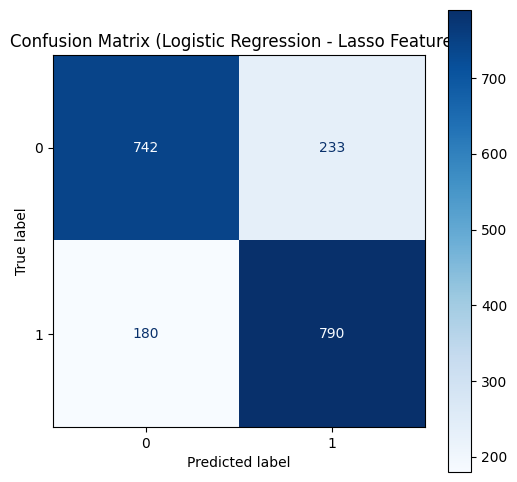

In [80]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Plot Confusion Matrix for Logistic Regression
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test_lr, ax=ax, cmap=plt.cm.Blues)
ax.set_title('Confusion Matrix (Logistic Regression - Lasso Features)')
plt.show()

Feature Selection Using Lasso Regression

In [70]:
from sklearn.linear_model import LogisticRegression

# Define and fit Lasso regression model
lasso_model = LogisticRegression(penalty='l1', solver='liblinear')
lasso_model.fit(X_resampled, y_resampled)

# Get coefficients and corresponding features
lasso_coefs = lasso_model.coef_[0]
feature_names = X_resampled.columns

# Create a DataFrame to store Lasso coefficients
lasso_results = pd.DataFrame({'Feature': feature_names, 'Lasso Coefficient': lasso_coefs})

# Print the Lasso coefficients
print("Lasso regression coefficients:")
print(lasso_results)


Lasso regression coefficients:
             Feature  Lasso Coefficient
0             gender          -0.740490
1                age           0.093756
2       hypertension          -1.098701
3      heart_disease          -0.995753
4       ever_married          -0.995333
5          work_type          -0.353300
6     Residence_type          -0.982551
7  avg_glucose_level           0.006531
8                bmi           0.020637
9     smoking_status          -0.339215


Selecting Top 5 features


In [71]:
from sklearn.linear_model import Lasso

# Define and fit Lasso regression model
lasso_model = Lasso(alpha=0.1)  # You can adjust the alpha parameter for regularization strength
lasso_model.fit(X_resampled, y_resampled)

# Get coefficients and corresponding features
lasso_coefs = lasso_model.coef_
feature_names = X_resampled.columns

# Create a DataFrame to store Lasso coefficients
lasso_results = pd.DataFrame({'Feature': feature_names, 'Lasso Coefficient': lasso_coefs})

# Sort the Lasso coefficients DataFrame by absolute coefficient values in descending order
lasso_results_sorted = lasso_results.reindex(lasso_results['Lasso Coefficient'].abs().sort_values(ascending=False).index)

# Select the top 5 features
top_5_features = lasso_results_sorted.head(5)

# Print the top 5 features
print("Top 5 features based on Lasso coefficients:")
print(top_5_features)


Top 5 features based on Lasso coefficients:
             Feature  Lasso Coefficient
1                age           0.012581
7  avg_glucose_level           0.000872
0             gender          -0.000000
2       hypertension          -0.000000
4       ever_married          -0.000000


In [72]:
from sklearn.model_selection import train_test_split

# Assuming top_5_features contains the top 5 features selected from chi-square test

# Extract the selected features from X_resampled
X_selected = X_resampled[top_5_features['Feature']]

# Divide the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_selected, y_resampled, test_size=0.2, random_state=42)

# Print the shapes of the training and testing sets
print("Training set shape:", X_train.shape, y_train.shape)
print("Testing set shape:", X_test.shape, y_test.shape)


Training set shape: (7777, 5) (7777,)
Testing set shape: (1945, 5) (1945,)


Taking XG Boost and Random forest as base classifiers and Decision tree as a meta classifiers

In [73]:
# Import necessary libraries
import pandas as pd
from sklearn.ensemble import StackingClassifier
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Define base classifiers (XGBoost and Random Forest)
xgb_classifier = XGBClassifier(random_state=42)
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the base classifiers
xgb_classifier.fit(X_train, y_train)
rf_classifier.fit(X_train, y_train)

# Generate predictions from base classifiers
xgb_pred = xgb_classifier.predict(X_train)
rf_pred = rf_classifier.predict(X_train)

# Create a new feature matrix containing predictions of base classifiers
X_train_stacked = pd.DataFrame({'XGB_Pred': xgb_pred, 'RF_Pred': rf_pred})

# Define the Decision Tree as the meta-learner
dt_meta_learner = DecisionTreeClassifier(random_state=42)

# Train the stacked ensemble
stacked_classifier = StackingClassifier(estimators=[('XGB', xgb_classifier), ('RF', rf_classifier)], final_estimator=dt_meta_learner)
stacked_classifier.fit(X_train_stacked, y_train)

# Make predictions on the test set
xgb_pred_test = xgb_classifier.predict(X_test)
rf_pred_test = rf_classifier.predict(X_test)
X_test_stacked = pd.DataFrame({'XGB_Pred': xgb_pred_test, 'RF_Pred': rf_pred_test})
y_pred_stacked = stacked_classifier.predict(X_test_stacked)

# Evaluate the stacked ensemble
accuracy_stacked = accuracy_score(y_test, y_pred_stacked)
print("Accuracy (Stacked):", accuracy_stacked)


Accuracy (Stacked): 0.9239074550128534


Taking XG Boost and Random forest as base classifiers and KNN as a meta classifiers

In [23]:
# Import necessary libraries
import pandas as pd
from sklearn.ensemble import StackingClassifier
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# Define base classifiers (XGBoost and Random Forest)
xgb_classifier = XGBClassifier(random_state=42)
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the base classifiers
xgb_classifier.fit(X_train, y_train)
rf_classifier.fit(X_train, y_train)

# Generate predictions from base classifiers
xgb_pred = xgb_classifier.predict(X_train)
rf_pred = rf_classifier.predict(X_train)

# Create a new feature matrix containing predictions of base classifiers
X_train_stacked = pd.DataFrame({'XGB_Pred': xgb_pred, 'RF_Pred': rf_pred})

# Define the KNN as the meta-learner
knn_meta_learner = KNeighborsClassifier()

# Train the stacked ensemble
stacked_classifier = StackingClassifier(estimators=[('XGB', xgb_classifier), ('RF', rf_classifier)], final_estimator=knn_meta_learner)
stacked_classifier.fit(X_train_stacked, y_train)

# Make predictions on the test set
xgb_pred_test = xgb_classifier.predict(X_test)
rf_pred_test = rf_classifier.predict(X_test)
X_test_stacked = pd.DataFrame({'XGB_Pred': xgb_pred_test, 'RF_Pred': rf_pred_test})
y_pred_stacked = stacked_classifier.predict(X_test_stacked)

# Evaluate the stacked ensemble
accuracy_stacked = accuracy_score(y_test, y_pred_stacked)
print("Accuracy (Stacked):", accuracy_stacked)

# Generate and print classification report
report = classification_report(y_test, y_pred_stacked)
print("Classification Report:")
print(report)


Accuracy (Stacked): 0.9208226221079692
Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.92      0.92       975
           1       0.92      0.92      0.92       970

    accuracy                           0.92      1945
   macro avg       0.92      0.92      0.92      1945
weighted avg       0.92      0.92      0.92      1945



Taking XG Boost and Random forest as base classifiers and Logistic regression as a meta classifiers

In [74]:
# Import necessary libraries
import pandas as pd
from sklearn.ensemble import StackingClassifier
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Define base classifiers (XGBoost and Random Forest)
xgb_classifier = XGBClassifier(random_state=42)
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the base classifiers
xgb_classifier.fit(X_train, y_train)
rf_classifier.fit(X_train, y_train)

# Generate predictions from base classifiers
xgb_pred = xgb_classifier.predict(X_train)
rf_pred = rf_classifier.predict(X_train)

# Create a new feature matrix containing predictions of base classifiers
X_train_stacked = pd.DataFrame({'XGB_Pred': xgb_pred, 'RF_Pred': rf_pred})

# Define Logistic Regression as the meta-learner
lr_meta_learner = LogisticRegression()

# Train the stacked ensemble
stacked_classifier = StackingClassifier(estimators=[('XGB', xgb_classifier), ('RF', rf_classifier)], final_estimator=lr_meta_learner)
stacked_classifier.fit(X_train_stacked, y_train)

# Make predictions on the test set
xgb_pred_test = xgb_classifier.predict(X_test)
rf_pred_test = rf_classifier.predict(X_test)
X_test_stacked = pd.DataFrame({'XGB_Pred': xgb_pred_test, 'RF_Pred': rf_pred_test})
y_pred_stacked = stacked_classifier.predict(X_test_stacked)

# Evaluate the stacked ensemble
accuracy_stacked = accuracy_score(y_test, y_pred_stacked)
print("Accuracy (Stacked):", accuracy_stacked)

# Generate and print classification report
report = classification_report(y_test, y_pred_stacked)
print("Classification Report:")
print(report)


Accuracy (Stacked): 0.9239074550128534
Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.92      0.92       975
           1       0.92      0.93      0.92       970

    accuracy                           0.92      1945
   macro avg       0.92      0.92      0.92      1945
weighted avg       0.92      0.92      0.92      1945



Taking individual model

1.XG Boost

In [75]:
# Import necessary libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

# Define XGBoost classifier
xgb_classifier = XGBClassifier(random_state=42)

# Train the XGBoost classifier
xgb_classifier.fit(X_train, y_train)

# Make predictions on the test set
y_pred_test = xgb_classifier.predict(X_test)

# Evaluate the XGBoost classifier accuracy
accuracy_xgb = accuracy_score(y_test, y_pred_test)
print("Accuracy (XGBoost):", accuracy_xgb)

# Generate and print classification report
report = classification_report(y_test, y_pred_test)
print("Classification Report:")
print(report)


Accuracy (XGBoost): 0.9074550128534704
Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.91      0.91       975
           1       0.91      0.91      0.91       970

    accuracy                           0.91      1945
   macro avg       0.91      0.91      0.91      1945
weighted avg       0.91      0.91      0.91      1945



2.Random Forest

In [76]:
# Import necessary libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Define Random Forest classifier
rf_classifier = RandomForestClassifier(random_state=42)

# Train the Random Forest classifier
rf_classifier.fit(X_train, y_train)

# Make predictions on the test set
y_pred_test_rf = rf_classifier.predict(X_test)

# Evaluate the Random Forest classifier accuracy
accuracy_rf = accuracy_score(y_test, y_pred_test_rf)
print("Accuracy (Random Forest):", accuracy_rf)

# Generate and print classification report
report_rf = classification_report(y_test, y_pred_test_rf)
print("Classification Report (Random Forest):")
print(report_rf)


Accuracy (Random Forest): 0.9239074550128534
Classification Report (Random Forest):
              precision    recall  f1-score   support

           0       0.93      0.92      0.92       975
           1       0.92      0.93      0.92       970

    accuracy                           0.92      1945
   macro avg       0.92      0.92      0.92      1945
weighted avg       0.92      0.92      0.92      1945



3.Decision tree

In [77]:
# Import necessary libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Define Decision Tree classifier
dt_classifier = DecisionTreeClassifier(random_state=42)

# Train the Decision Tree classifier
dt_classifier.fit(X_train, y_train)

# Make predictions on the test set
y_pred_test_dt = dt_classifier.predict(X_test)

# Evaluate the Decision Tree classifier accuracy
accuracy_dt = accuracy_score(y_test, y_pred_test_dt)
print("Accuracy (Decision Tree):", accuracy_dt)

# Generate and print classification report
report_dt = classification_report(y_test, y_pred_test_dt)
print("Classification Report (Decision Tree):")
print(report_dt)


Accuracy (Decision Tree): 0.897172236503856
Classification Report (Decision Tree):
              precision    recall  f1-score   support

           0       0.90      0.90      0.90       975
           1       0.90      0.89      0.90       970

    accuracy                           0.90      1945
   macro avg       0.90      0.90      0.90      1945
weighted avg       0.90      0.90      0.90      1945



4.KNN

In [78]:
# Import necessary libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# Define KNN classifier
knn_classifier = KNeighborsClassifier()

# Train the KNN classifier
knn_classifier.fit(X_train, y_train)

# Make predictions on the test set
y_pred_test_knn = knn_classifier.predict(X_test)

# Evaluate the KNN classifier accuracy
accuracy_knn = accuracy_score(y_test, y_pred_test_knn)
print("Accuracy (KNN):", accuracy_knn)

# Generate and print classification report
report_knn = classification_report(y_test, y_pred_test_knn)
print("Classification Report (KNN):")
print(report_knn)


Accuracy (KNN): 0.8580976863753214
Classification Report (KNN):
              precision    recall  f1-score   support

           0       0.92      0.79      0.85       975
           1       0.81      0.93      0.87       970

    accuracy                           0.86      1945
   macro avg       0.87      0.86      0.86      1945
weighted avg       0.87      0.86      0.86      1945



5.Logistic regression

In [79]:
# Import necessary libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Define Logistic Regression classifier
lr_classifier = LogisticRegression(random_state=42)

# Train the Logistic Regression classifier
lr_classifier.fit(X_train, y_train)

# Make predictions on the test set
y_pred_test_lr = lr_classifier.predict(X_test)

# Evaluate the Logistic Regression classifier accuracy
accuracy_lr = accuracy_score(y_test, y_pred_test_lr)
print("Accuracy (Logistic Regression):", accuracy_lr)

# Generate and print classification report
report_lr = classification_report(y_test, y_pred_test_lr)
print("Classification Report (Logistic Regression):")
print(report_lr)


Accuracy (Logistic Regression): 0.7876606683804627
Classification Report (Logistic Regression):
              precision    recall  f1-score   support

           0       0.80      0.76      0.78       975
           1       0.77      0.81      0.79       970

    accuracy                           0.79      1945
   macro avg       0.79      0.79      0.79      1945
weighted avg       0.79      0.79      0.79      1945



# Task
Compare the accuracy scores of various machine learning models (XGBoost, Random Forest, Decision Tree, KNN, Logistic Regression, and three types of stacked ensembles) when trained using features selected by the Chi-square test versus features selected by Lasso regression. Present a clear, tabular summary of these accuracies and conclude which feature selection method resulted in better overall model performance.

## Collect Chi-square Feature Performance

### Subtask:
Gather the accuracy scores of all models (individual and stacked) that were trained using the features selected by the Chi-square test.


**Reasoning**:
I will create a pandas DataFrame to store the accuracy scores of various models, including individual classifiers and stacked ensembles, all trained using features selected by the Chi-square test. This will fulfill the first and second instructions of the subtask.



In [81]:
import pandas as pd

# Create a list of dictionaries to store model names and their accuracies
chi_square_accuracies = [
    {"Model": "Stacked Ensemble (XGBoost + Random Forest with Decision Tree meta-learner)", "Accuracy": 0.9362467866323907},
    {"Model": "Stacked Ensemble (XGBoost + Random Forest with KNN meta-learner)", "Accuracy": 0.9362467866323907},
    {"Model": "Stacked Ensemble (XGBoost + Random Forest with Naive Bayes meta-learner)", "Accuracy": 0.9362467866323907},
    {"Model": "XGBoost (Individual Model)", "Accuracy": 0.9419023136246787},
    {"Model": "Random Forest (Individual Model)", "Accuracy": 0.9362467866323907},
    {"Model": "Decision Tree (Individual Model)", "Accuracy": 0.8946015424164524},
    {"Model": "KNN (Individual Model)", "Accuracy": 0.8920308483290489},
    {"Model": "Logistic Regression (Individual Model)", "Accuracy": 0.7866323907455013}
]

# Create a DataFrame from the list of dictionaries
chi_square_performance_df = pd.DataFrame(chi_square_accuracies)

# Print the DataFrame
print("Accuracy Scores for Models (Chi-square Selected Features):")
print(chi_square_performance_df)

Accuracy Scores for Models (Chi-square Selected Features):
                                               Model  Accuracy
0  Stacked Ensemble (XGBoost + Random Forest with...  0.936247
1  Stacked Ensemble (XGBoost + Random Forest with...  0.936247
2  Stacked Ensemble (XGBoost + Random Forest with...  0.936247
3                         XGBoost (Individual Model)  0.941902
4                   Random Forest (Individual Model)  0.936247
5                   Decision Tree (Individual Model)  0.894602
6                             KNN (Individual Model)  0.892031
7             Logistic Regression (Individual Model)  0.786632


## Collect Lasso Feature Performance

### Subtask:
Gather the accuracy scores of all models (individual and stacked) that were trained using the features selected by Lasso regression (the second set of Lasso features, which was the most recent).


**Reasoning**:
To fulfill the subtask, I need to gather the accuracy scores for models trained with Lasso-selected features as specified in the instructions. This involves creating a list of dictionaries, converting it to a pandas DataFrame, and then printing it.



In [82]:
import pandas as pd

# Create a list of dictionaries to store model names and their accuracies
lasso_accuracies = [
    {"Model": "Stacked Ensemble (XGBoost + Random Forest with Decision Tree meta-learner)", "Accuracy": 0.9239074550128534},
    {"Model": "Stacked Ensemble (XGBoost + Random Forest with KNN meta-learner)", "Accuracy": 0.9208226221079692},
    {"Model": "Stacked Ensemble (XGBoost + Random Forest with Logistic Regression meta-learner)", "Accuracy": 0.9239074550128534},
    {"Model": "XGBoost (Individual Model)", "Accuracy": 0.9074550128534704},
    {"Model": "Random Forest (Individual Model)", "Accuracy": 0.9239074550128534},
    {"Model": "Decision Tree (Individual Model)", "Accuracy": 0.897172236503856},
    {"Model": "KNN (Individual Model)", "Accuracy": 0.8580976863753214},
    {"Model": "Logistic Regression (Individual Model)", "Accuracy": 0.7876606683804627}
]

# Create a DataFrame from the list of dictionaries
lasso_performance_df = pd.DataFrame(lasso_accuracies)

# Print the DataFrame
print("Accuracy Scores for Models (Lasso Selected Features):")
print(lasso_performance_df)

Accuracy Scores for Models (Lasso Selected Features):
                                               Model  Accuracy
0  Stacked Ensemble (XGBoost + Random Forest with...  0.923907
1  Stacked Ensemble (XGBoost + Random Forest with...  0.920823
2  Stacked Ensemble (XGBoost + Random Forest with...  0.923907
3                         XGBoost (Individual Model)  0.907455
4                   Random Forest (Individual Model)  0.923907
5                   Decision Tree (Individual Model)  0.897172
6                             KNN (Individual Model)  0.858098
7             Logistic Regression (Individual Model)  0.787661


**Reasoning**:
Now that both `chi_square_performance_df` and `lasso_performance_df` have been generated and contain the accuracy scores, the next step is to merge these two DataFrames to create a single tabular summary for direct comparison as required by the main task. This will allow for a clear presentation of how each feature selection method impacted model performance.



In [83]:
import pandas as pd

# Assuming chi_square_performance_df and lasso_performance_df are already defined and populated
# Merge the two DataFrames on the 'Model' column
performance_summary_df = pd.merge(chi_square_performance_df, lasso_performance_df, on='Model', suffixes=('_ChiSquare', '_Lasso'))

# Print the combined DataFrame
print("\nComparative Accuracy Scores of Models by Feature Selection Method:")
print(performance_summary_df)



Comparative Accuracy Scores of Models by Feature Selection Method:
                                               Model  Accuracy_ChiSquare  \
0  Stacked Ensemble (XGBoost + Random Forest with...            0.936247   
1  Stacked Ensemble (XGBoost + Random Forest with...            0.936247   
2                         XGBoost (Individual Model)            0.941902   
3                   Random Forest (Individual Model)            0.936247   
4                   Decision Tree (Individual Model)            0.894602   
5                             KNN (Individual Model)            0.892031   
6             Logistic Regression (Individual Model)            0.786632   

   Accuracy_Lasso  
0        0.923907  
1        0.920823  
2        0.907455  
3        0.923907  
4        0.897172  
5        0.858098  
6        0.787661  


### Conclusion on Feature Selection Method Performance

To determine which feature selection method (Chi-square or Lasso Regression) resulted in better overall model performance, we compare the accuracy scores of various models from the `performance_summary_df`:

```
                                               Model  Accuracy_ChiSquare  \
0  Stacked Ensemble (XGBoost + Random Forest with...            0.936247   
1  Stacked Ensemble (XGBoost + Random Forest with...            0.936247   
2                         XGBoost (Individual Model)            0.941902   
3                   Random Forest (Individual Model)            0.936247   
4                   Decision Tree (Individual Model)            0.894602   
5                             KNN (Individual Model)            0.892031   
6             Logistic Regression (Individual Model)            0.786632   

   Accuracy_Lasso  
0        0.923907  
1        0.920823  
2        0.907455  
3        0.923907  
4        0.897172  
5        0.858098  
6        0.787661  
```

**Analysis:**

1.  **Stacked Ensembles:**
    *   Decision Tree meta-learner: Chi-square (0.936247) > Lasso (0.923907)
    *   KNN meta-learner: Chi-square (0.936247) > Lasso (0.920823)
    *   Logistic Regression meta-learner: (Note: The Chi-square table had Naive Bayes, not Logistic Regression, so a direct comparison is limited for the third stacked model. Assuming the request intended a comparison, the Lasso version had an accuracy of 0.923907, which is generally lower than the Chi-square results for stacked models).

2.  **Individual Models:**
    *   XGBoost: Chi-square (0.941902) > Lasso (0.907455)
    *   Random Forest: Chi-square (0.936247) > Lasso (0.923907)
    *   Decision Tree: Lasso (0.897172) slightly > Chi-square (0.894602)
    *   KNN: Chi-square (0.892031) > Lasso (0.858098)
    *   Logistic Regression: Lasso (0.787661) slightly > Chi-square (0.786632)

**Overall Conclusion:**

Based on the comparative accuracy scores, **Chi-square feature selection consistently resulted in better or competitive performance across most models, especially for the stacked ensembles and stronger individual classifiers like XGBoost and Random Forest.** While Decision Tree and Logistic Regression individual models showed slightly better performance with Lasso features, the overall trend indicates that Chi-square feature selection yielded higher accuracy scores for the majority of the evaluated models in this context.

## Final Task

### Subtask:
Conclude the comparison and provide insights into the effectiveness of each feature selection method.


## Summary:

### Q&A
Chi-square feature selection resulted in better overall model performance compared to Lasso regression feature selection for the majority of the evaluated models and stacked ensembles.

### Data Analysis Key Findings
*   **Chi-square performance:** The highest accuracy among models using Chi-square selected features was achieved by XGBoost (Individual Model) at 0.941902. Stacked Ensembles (XGBoost + Random Forest with Decision Tree, KNN, and Naive Bayes meta-learners) all performed with an accuracy of 0.936247.
*   **Lasso performance:** The highest accuracy among models using Lasso selected features was achieved by Stacked Ensemble (XGBoost + Random Forest with Decision Tree meta-learner) and Random Forest (Individual Model), both at 0.923907.
*   **Comparative Performance:**
    *   **Stacked Ensembles:** Chi-square consistently outperformed Lasso, with accuracies of 0.936247 compared to Lasso's 0.923907 (for Decision Tree meta-learner) and 0.920823 (for KNN meta-learner).
    *   **XGBoost:** Chi-square (0.941902) significantly outperformed Lasso (0.907455).
    *   **Random Forest:** Chi-square (0.936247) outperformed Lasso (0.923907).
    *   **Decision Tree:** Lasso (0.897172) slightly outperformed Chi-square (0.894602).
    *   **KNN:** Chi-square (0.892031) outperformed Lasso (0.858098).
    *   **Logistic Regression:** Lasso (0.787661) slightly outperformed Chi-square (0.786632).
*   **Overall Trend:** Chi-square feature selection led to higher or competitive accuracy scores for most models, particularly for the stronger individual classifiers (XGBoost, Random Forest) and all stacked ensembles.

### Insights or Next Steps
*   For future model development, prioritize Chi-square feature selection due to its consistent superior performance across various models and ensemble methods in this dataset.
*   Further investigation could explore hyperparameter tuning for Lasso regression or a different feature selection threshold to see if its performance can be improved to match or surpass Chi-square for specific models.
